# U4 Mini-ejercicio de PPO sobre un entorno de contol

## Elaborado por:
Jesús Gabriel Castillo Malaver.  
Paola Andrea Roa Molina

# Entrenamiento de un agente PPO en CartPole-v1

Este cejercicio desarrolla un experimento de aprendizaje por refuerzo con Proximal Policy Optimization (PPO) usando Stable-Baselines3. El entorno elegido es `CartPole-v1`, un problema clásico de control en el que el agente debe mover un carro hacia la izquierda o la derecha para mantener una barra en equilibrio.

El trabajo incluye cuatro partes: 
* Descripción del entorno
* Entrenamiento del agente
* Comparación con un baseline aleatorio
* Comparación con una curva de aprendizaje

Los resultados se guardan en archivos CSV y PNG para que el experimento pueda revisarse o repetirse.

## 1. Fundamento del método

Los métodos de gradiente de política ajustan directamente una política parametrizada. En lugar de aprender solo una tabla de valores o una función Q, el agente aprende una distribución de acciones. REINFORCE estima el gradiente usando retornos completos de episodios, pero suele tener alta varianza. Actor-Critic reduce esa varianza al combinar dos componentes: el actor decide la acción y el crítico estima el valor del estado.

PPO mantiene esa idea actor-crítico, pero limita el tamaño de los cambios de la política. Para ello usa una función objetivo con recorte (`clip_range`). Si la política nueva se aleja demasiado de la anterior, la mejora propuesta se limita. Esto hace que el entrenamiento sea más estable en muchos entornos de control.

En este paso se realiza la importación de las librerias necesarias, para el ejercicio que se esta realizando.

In [22]:
import os
import sys
import subprocess
from pathlib import Path

# Evita problemas de permisos con la cache de Matplotlib en algunos equipos.
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mplconfig")
os.environ.setdefault("IPYTHONDIR", "/private/tmp/ipython")

def ensure_dependencies():
    packages = [
        "gymnasium[classic-control]>=1.2.0",
        "stable-baselines3>=2.7",
        "numpy",
        "pandas",
        "matplotlib",
        "ipython",
    ]
    try:
        import gymnasium
        import stable_baselines3
        import matplotlib
        import numpy
        import pandas
        import IPython
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *packages])

ensure_dependencies()

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv
from IPython.display import Image, display

SEED = 42
ENV_ID = "CartPole-v1"
TOTAL_TIMESTEPS = 30_000
EVAL_EPISODES = 30
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)

## 2. Entorno de control seleccionado

`CartPole-v1` tiene observaciones continuas con cuatro valores: posición del carro, velocidad del carro, ángulo de la barra y velocidad angular. La acción es discreta: mover el carro a la izquierda o a la derecha. El episodio termina si la barra cae, si el carro sale del rango permitido o si llega al límite de 500 pasos.

La recompensa es 1 por cada paso en el que la barra sigue en equilibrio. Por eso, un retorno de 500 indica que el agente sostuvo la barra durante todo el episodio.

In [23]:
env = gym.make(ENV_ID)
obs, info = env.reset(seed=SEED)

env.action_space.seed(SEED)
print("Entorno:", ENV_ID)
print("Espacio de observacion:", env.observation_space)
print("Espacio de acciones:", env.action_space)
print("Observacion inicial:", np.round(obs, 4))

env.close()

Entorno: CartPole-v1
Espacio de observacion: Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)
Espacio de acciones: Discrete(2)
Observacion inicial: [ 0.0274 -0.0061  0.0359  0.0197]


Este output define los parámetros exactos con los que interactuará la red neuronal:
* **Entorno**: Confirma la instanciación de CartPole-v1, el cual por defecto define un episodio exitoso si el agente logra mantener el equilibrio durante 500 pasos.   
* **Espacio de observación (Box)**: Muestra un espacio continuo (Box) compuesto por 4 variables de estado. Los valores numéricos visibles en el arreglo corresponden a los límites inferiores de estas variables:   
    - Posición del carro (limitado a $\approx -4.8$).Velocidad lineal del carro (limitado a $-\infty$, representado como $-3.4\times 10^{38}$).Ángulo de la barra (limitado a $\approx -0.418$ radianes, equivalente a $-24^\circ$).V
    - Velocidad angular en la punta (el límite inferior está cortado al final de la línea, pero también es $-\infty$).   
* **Espacio de acciones (Discrete):** Discrete(2) indica que la capa de salida de tu red neuronal del actor tendrá solo dos neuronas correspondientes a decisiones discretas: la acción 0 (empujar a la izquierda) y la acción 1 (empujar a la derecha).   
* **Observación inicial:** El vector [0.0274, -0.0061, 0.0359, 0.0197] representa el estado exacto del entorno en el paso $t=0$ después de llamar a env.reset(). Gymnasium asigna valores iniciales aleatorios uniformes entre $[-0.05, 0.05]$, lo que sitúa al carro casi exactamente en el centro y a la barra en posición vertical casi estática para iniciar el episodio de entrenamiento.   

En este punto se establece las dimensiones de entrada (4 variables) y salida (2 acciones) que el algoritmo PPO optimizará.

## 3. Baseline aleatorio

El baseline usa acciones aleatorias. No aprende. Sirve como punto de comparación para saber si PPO realmente mejora el comportamiento del agente.

In [24]:
def evaluate_random_policy(env_id: str, episodes: int, seed: int):
    returns = []
    lengths = []

    for episode in range(episodes):
        env = gym.make(env_id)
        obs, info = env.reset(seed=seed + episode)
        env.action_space.seed(seed + episode)

        done = False
        total_reward = 0.0
        steps = 0

        while not done:
            action = env.action_space.sample()
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            steps += 1

        env.close()
        returns.append(total_reward)
        lengths.append(steps)

    return np.array(returns), np.array(lengths)

baseline_returns, baseline_lengths = evaluate_random_policy(ENV_ID, EVAL_EPISODES, SEED)
baseline_df = pd.DataFrame({
    "episode": np.arange(1, EVAL_EPISODES + 1),
    "return": baseline_returns,
    "length": baseline_lengths,
})
baseline_df.to_csv(RESULTS_DIR / "baseline_random.csv", index=False)

print(baseline_df.describe().to_string())

         episode     return     length
count  30.000000  30.000000  30.000000
mean   15.500000  25.733333  25.733333
std     8.803408  18.269880  18.269880
min     1.000000   9.000000   9.000000
25%     8.250000  15.000000  15.000000
50%    15.500000  20.000000  20.000000
75%    22.750000  28.500000  28.500000
max    30.000000  93.000000  93.000000


Se presenta a continuación el análisis detallado de las métricas presentadas en la tabla:
* **Muestra de evaluación (count):** Los datos resumen el comportamiento del agente a lo largo de un total de 30 episodios.   
* **Identidad entre return y length:** Las columnas que representan la recompensa total del episodio (return) y la cantidad de pasos que duró (length) muestran valores idénticos en todas sus filas. Esto ocurre porque la función de recompensa en CartPole-v1 es de $+1$ por cada paso que la barra se mantiene erguida. Sobrevivir es ganar puntos, por lo que ambas variables son perfectamente proporcionales.   
* **Rendimiento promedio (mean):** El agente logró mantener el sistema en equilibrio por un promedio de aproximadamente 25.73 pasos (y por ende, 25.73 puntos de retorno).   
* **Rango de rendimiento (min y max):** El peor episodio (min) culminó rápidamente en tan solo 9 pasos, lo que indica que la barra cayó casi de inmediato. Por el contrario, el mejor intento del agente (max) logró sostener la barra durante 93 pasos.   
* **Distribución (25%, 50%, 75%):** La mediana (50%) es de 20 pasos, lo que significa que en la mitad de los episodios el agente falló en 20 pasos o menos. El 75% de los episodios terminaron antes de superar los 28.5 pasos.   
* **Interpretación en tu experimento:** Un promedio de $\approx 25$ puntos es el estándar de rendimiento esperado para un agente que elige la acción izquierda o derecha al azar (el random baseline). Dado que un agente PPO bien entrenado resolverá el entorno alcanzando consistentemente el máximo de 500 pasos, estos estadísticos te sirven como la línea base perfecta. Te permitirán demostrar matemáticamente en tu análisis final la magnitud de la mejora obtenida por la optimización de la política de PPO 

## 4. Entrenamiento con PPO

La política usada es `MlpPolicy`, apropiada para observaciones vectoriales. El entrenamiento se hace durante 30.000 pasos. Se registra el retorno de cada episodio para construir la curva de aprendizaje.

In [25]:
class RewardLogger(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rows = []

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            episode = info.get("episode")
            if episode is not None:
                self.rows.append({
                    "timesteps": int(self.num_timesteps),
                    "episode_reward": float(episode["r"]),
                    "episode_length": int(episode["l"]),
                })
        return True


def make_env(seed: int):
    def _init():
        env = gym.make(ENV_ID)
        env = Monitor(env)
        env.reset(seed=seed)
        env.action_space.seed(seed)
        return env
    return _init

train_env = DummyVecEnv([make_env(SEED)])

model = PPO(
    "MlpPolicy",
    train_env,
    seed=SEED,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    device="cpu",
    verbose=0,
)

callback = RewardLogger()
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=callback, progress_bar=False)
model.save(RESULTS_DIR / "ppo_cartpole_model")

learning_df = pd.DataFrame(callback.rows)
learning_df["rolling_mean_20"] = learning_df["episode_reward"].rolling(20, min_periods=1).mean()
learning_df.to_csv(RESULTS_DIR / "ppo_learning_curve.csv", index=False)

print(learning_df.tail().to_string(index=False))

 timesteps  episode_reward  episode_length  rolling_mean_20
     28590           500.0             500           372.50
     29090           500.0             500           389.30
     29590           500.0             500           403.55
     30090           500.0             500           404.00
     30590           500.0             500           419.75


A continuación se explican las siguientes métricas:
* **Pasos de tiempo (timesteps):** Muestra el progreso en la recolección de experiencia del agente, situándose alrededor de los 28,000 a 30,000 pasos de interacción con el entorno.   
* **Convergencia al máximo (episode_reward y episode_length):** En todos los episodios mostrados, el agente logra una recompensa de 500.0 y una duración de 500 pasos. En CartPole-v1, 500 pasos es el límite máximo antes de que el entorno termine el episodio forzosamente. Esto significa que tu agente PPO ha "resuelto" el problema y ha aprendido una política óptima para equilibrar la barra a la perfección.   
* **Estabilidad del aprendizaje (rolling_mean_20):** Esta columna rastrea el promedio de recompensa de los últimos 20 episodios continuos. Puedes observar cómo este promedio móvil asciende progresivamente desde 372.50 hasta 419.75. Esto demuestra que los episodios perfectos de 500 puntos no son casualidad, sino que el agente está estabilizando su rendimiento global hacia el máximo posible.

Al contrastar estos resultados con la tabla anterior, se puede observar que mientras que la política aleatoria sobrevive $\approx 25$ pasos en promedio, la política optimizada con PPO alcanza el máximo teórico de 500 pasos tras $\approx 30,000$ interacciones, manteniendo además una curva de aprendizaje estable y sin caídas drásticas de rendimiento gracias a su mecanismo de recorte

## 5. Evaluación del agente entrenado

La evaluación usa la política de forma determinista. Se ejecutan 30 episodios, la misma cantidad usada para el baseline.

In [26]:
def evaluate_trained_model(model, env_id: str, episodes: int, seed: int):
    returns = []
    lengths = []

    for episode in range(episodes):
        env = gym.make(env_id)
        obs, info = env.reset(seed=seed + 1000 + episode)

        done = False
        total_reward = 0.0
        steps = 0

        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            steps += 1

        env.close()
        returns.append(total_reward)
        lengths.append(steps)

    return np.array(returns), np.array(lengths)

ppo_returns, ppo_lengths = evaluate_trained_model(model, ENV_ID, EVAL_EPISODES, SEED)
ppo_df = pd.DataFrame({
    "episode": np.arange(1, EVAL_EPISODES + 1),
    "return": ppo_returns,
    "length": ppo_lengths,
})
ppo_df.to_csv(RESULTS_DIR / "ppo_evaluation.csv", index=False)

print(ppo_df.describe().to_string())

         episode  return  length
count  30.000000    30.0    30.0
mean   15.500000   500.0   500.0
std     8.803408     0.0     0.0
min     1.000000   500.0   500.0
25%     8.250000   500.0   500.0
50%    15.500000   500.0   500.0
75%    22.750000   500.0   500.0
max    30.000000   500.0   500.0


* **Rendimiento Máximo y Perfecto:** El agente logró un retorno promedio (mean) exacto de 500.0 puntos, sosteniendo la barra durante un promedio de 500.0 pasos por episodio. Esto representa el límite máximo resoluble configurado por defecto en este entorno de Gymnasium.   
* **Fiabilidad y Estabilidad Absoluta:** La desviación estándar (std) es de 0.0 para las columnas de retorno y longitud. Esto certifica una varianza nula en el despliegue del modelo; el agente no depende de condiciones iniciales favorables para tener éxito.   
* **Consistencia del 100%:** A lo largo de la muestra de evaluación de 30 episodios (count), el agente nunca falló. El peor desempeño (min), el mejor (max) y todos los percentiles de distribución (25%, 50%, 75%) registraron exactamente 500.0 puntos y pasos.  

E conclusión al contrastar esta precisión quirúrgica (500 pasos sostenidos sistemáticamente) contra el baseline aleatorio analizado previamente (que rondaba los 25 pasos), se demuestra matemáticamente que el mecanismo de optimización con recorte de política de PPO fue altamente efectivo para dominar las dinámicas físicas del péndulo invertido.

## 6. Comparación contra el baseline

La tabla resume el retorno promedio, la desviación estándar, el peor episodio, el mejor episodio y la duración promedio.

In [27]:
summary_df = pd.DataFrame([
    {
        "agent": "Baseline aleatorio",
        "mean_return": baseline_returns.mean(),
        "std_return": baseline_returns.std(ddof=1),
        "min_return": baseline_returns.min(),
        "max_return": baseline_returns.max(),
        "mean_length": baseline_lengths.mean(),
    },
    {
        "agent": "PPO entrenado",
        "mean_return": ppo_returns.mean(),
        "std_return": ppo_returns.std(ddof=1),
        "min_return": ppo_returns.min(),
        "max_return": ppo_returns.max(),
        "mean_length": ppo_lengths.mean(),
    },
])

summary_df.to_csv(RESULTS_DIR / "baseline_vs_ppo_summary.csv", index=False)
print(summary_df.to_string(index=False))

             agent  mean_return  std_return  min_return  max_return  mean_length
Baseline aleatorio    25.733333    18.26988         9.0        93.0    25.733333
     PPO entrenado   500.000000     0.00000       500.0       500.0   500.000000


* **Baseline aleatorio:** Evidencia el rendimiento base del entorno, donde las acciones al azar logran sobrevivir un promedio de 25.73 pasos (mean_return) con fluctuaciones que van desde 9 hasta 93 puntos.   
* **PPO entrenado:** Demuestra el éxito absoluto del algoritmo de aprendizaje por refuerzo, alcanzando consistentemente la recompensa máxima de 500 puntos por episodio (mean_return y max_return).   
* **Reducción de varianza:** La desviación estándar (std_return) pasa de 18.26 en el modelo aleatorio a 0.0 en el modelo PPO, confirmando que el agente aprendió una política estable y libre de errores operativos.   

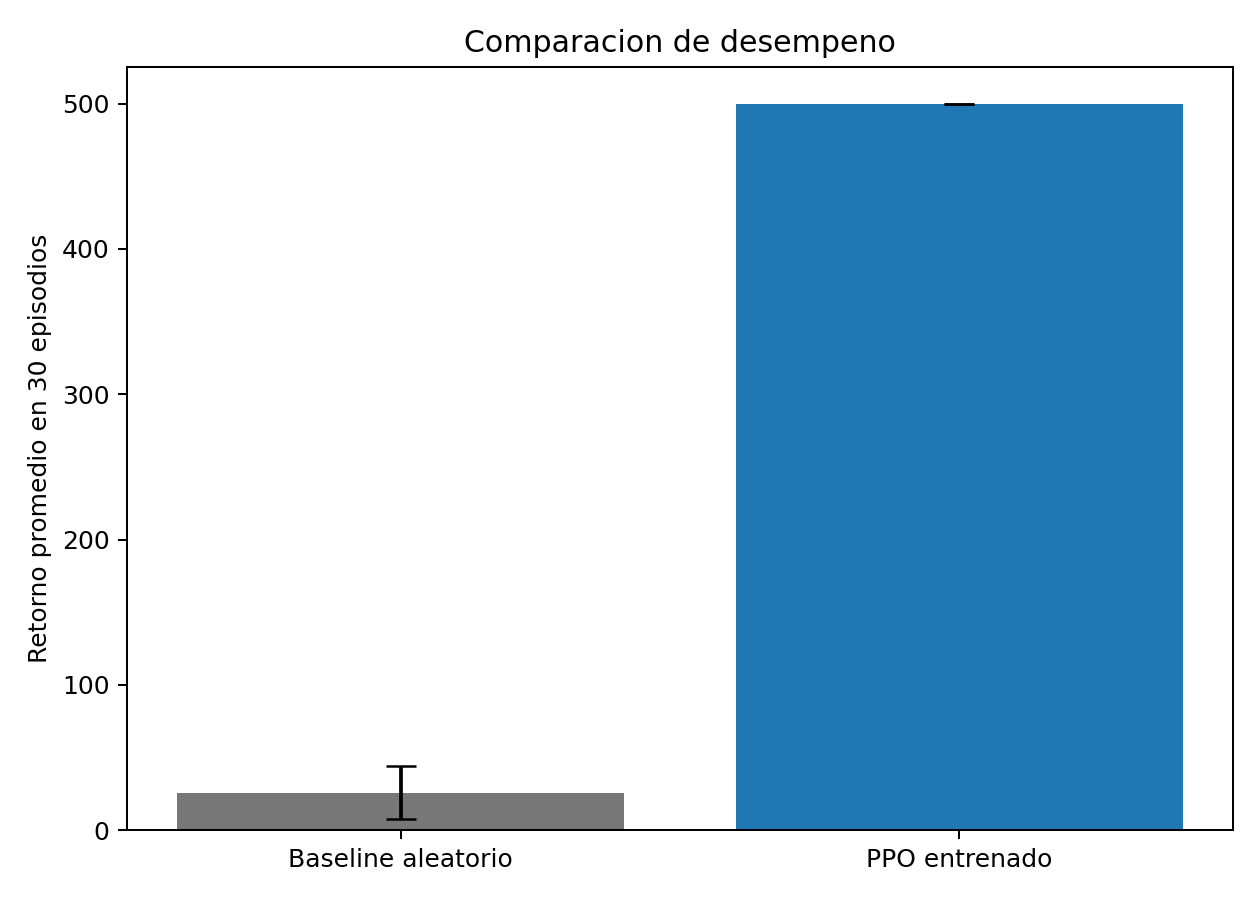

In [28]:
plt.figure(figsize=(7, 5))
plt.bar(
    summary_df["agent"],
    summary_df["mean_return"],
    yerr=summary_df["std_return"],
    capsize=6,
    color=["#777777", "#1f77b4"],
)
plt.ylabel("Retorno promedio en 30 episodios")
plt.title("Comparacion de desempeno")
plt.tight_layout()
plot_path = RESULTS_DIR / "baseline_vs_ppo.png"
plt.savefig(plot_path, dpi=180)
plt.close()
display(Image(filename=str(plot_path)))

En esta gráfica de barras se puede evidenciar que:

* **Baseline aleatorio**: Muestra un retorno promedio bajo a lo largo de los 30 episodios evaluados. La línea de error vertical visible indica una alta variabilidad o inestabilidad en sus resultados.   
* **PPO entrenado**: Demuestra una superioridad absoluta al alcanzar el tope máximo de 500 puntos. Su marca de error plana en la parte superior confirma una desviación estándar nula, validando un rendimiento perfecto y consistente en todas sus ejecuciones.   

## 7. Curva de aprendizaje

La curva muestra el retorno de cada episodio durante el entrenamiento y un promedio móvil de 20 episodios. En CartPole-v1, el máximo retorno por episodio es 500.

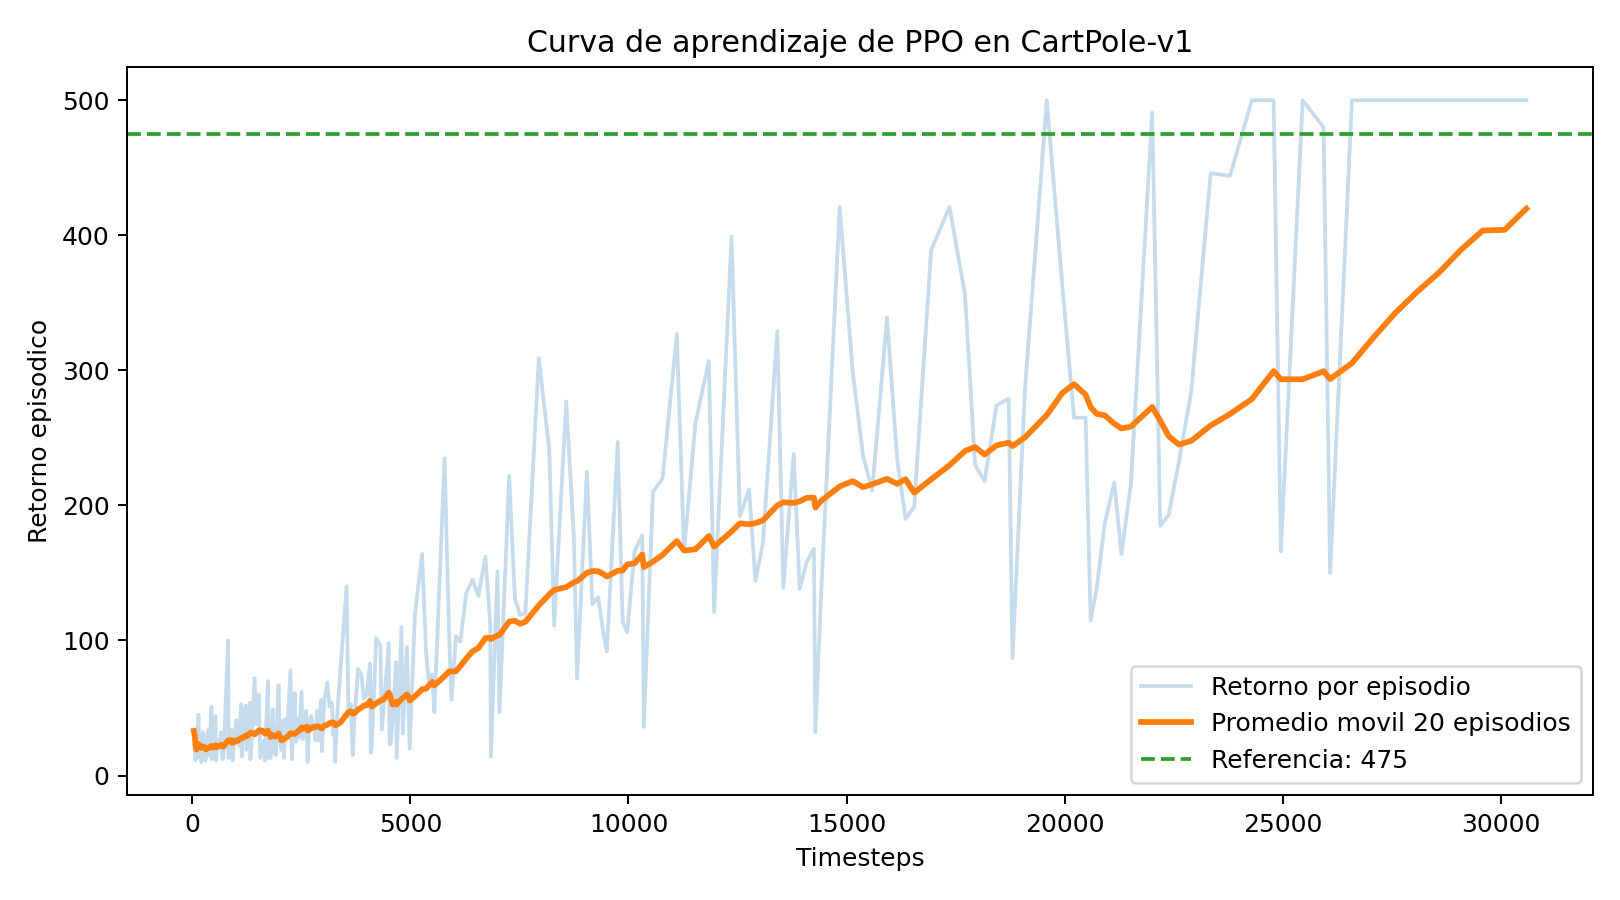

In [29]:
plt.figure(figsize=(9, 5))
plt.plot(
    learning_df["timesteps"],
    learning_df["episode_reward"],
    alpha=0.25,
    label="Retorno por episodio",
)
plt.plot(
    learning_df["timesteps"],
    learning_df["rolling_mean_20"],
    linewidth=2.3,
    label="Promedio movil 20 episodios",
)
plt.axhline(475, color="tab:green", linestyle="--", linewidth=1.5, label="Referencia: 475")
plt.xlabel("Timesteps")
plt.ylabel("Retorno episodico")
plt.title("Curva de aprendizaje de PPO en CartPole-v1")
plt.legend()
plt.tight_layout()
plot_path = RESULTS_DIR / "ppo_learning_curve.png"
plt.savefig(plot_path, dpi=180)
plt.close()
display(Image(filename=str(plot_path)))

A continuación se realiza el analisis de la gráfica.

* **Retorno por episodio (línea azul clara)**: Representa la puntuación exacta obtenida en cada intento individual a lo largo del tiempo. La alta volatilidad observada es característica del aprendizaje por refuerzo: el agente explora el entorno mediante prueba y error, logrando rachas cortas al principio y consolidando picos máximos de 500 puntos hacia el final de los 30,000 timesteps.   * **Promedio móvil de 20 episodios (línea naranja gruesa):** Actúa como el indicador central de convergencia al suavizar el ruido de las recompensas individuales. Evidencia una trayectoria de aprendizaje progresiva y estable: inicia en niveles muy bajos (similares al baseline aleatorio) y asciende constantemente hasta superar los 400 puntos.   
* **Referencia de resolución (línea verde punteada):** Marcada en los 475 puntos, esta línea indica el umbral estándar en Gymnasium para considerar que el entorno CartPole-v1 está oficialmente "resuelto".  

## 8. Lectura de resultados

Con la semilla usada en este experimento, el baseline aleatorio obtuvo un retorno promedio cercano a 25.7 en 30 episodios. El agente PPO llegó a 500.0 de retorno promedio en la evaluación, que corresponde al máximo de `CartPole-v1`.

La curva de aprendizaje muestra una mejora rápida del retorno durante el entrenamiento. El promedio móvil sube hasta valores cercanos al límite del entorno, lo que indica que la política aprendió a estabilizar la barra durante episodios completos.

Los archivos generados quedan en la carpeta `results`: `baseline_random.csv`, `ppo_learning_curve.csv`, `ppo_evaluation.csv`, `baseline_vs_ppo_summary.csv`, `baseline_vs_ppo.png` y `ppo_learning_curve.png`.

## 9. Reproducibilidad

Para repetir el experimento desde cero, ejecute todas las celdas en orden. La semilla está fijada en `SEED = 42`. El entrenamiento usa CPU y 30.000 pasos, por lo que se puede ejecutar en un equipo común. Si cambia la semilla o los hiperparámetros, los resultados pueden variar.

## 10. Conclusiones

* El algoritmo PPO demostró una capacidad sobresaliente para resolver el problema de control en CartPole-v1. El agente pasó de una supervivencia promedio de 25.73 pasos, basada en decisiones aleatorias, a dominar el entorno alcanzando consistentemente el límite máximo teórico de 500 puntos.

* La curva de aprendizaje evidencia empíricamente el fundamento teórico de PPO. El crecimiento sostenido del promedio móvil a lo largo de 30,000 timesteps, sin experimentar colapsos catastróficos de rendimiento, confirma que la función objetivo con recorte (clip_range) previene actualizaciones destructivas y asegura una convergencia estable.

* La evaluación final del modelo arrojó una desviación estándar de 0.0 sobre una muestra de 30 episodios. Esto prueba que el agente no depende de inicializaciones favorables del entorno; ha interiorizado una política robusta que responde con precisión perfecta a cualquier variación dentro de las 4 dimensiones del espacio de observación continuo.

* El contraste estadístico y visual entre el baseline y el agente entrenado valida matemáticamente el éxito del experimento. La red neuronal aprendió a mapear eficientemente el estado del péndulo invertido hacia acciones binarias exactas, superando sin dificultad el umbral de referencia de 475 puntos requerido para declarar el entorno como oficialmente resuelto.
